=== TUGAS UTS - Marselina Londa - RS 35 ===
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Theta: [28.05748153  9.23660641]
MSE: 49.756024928644194


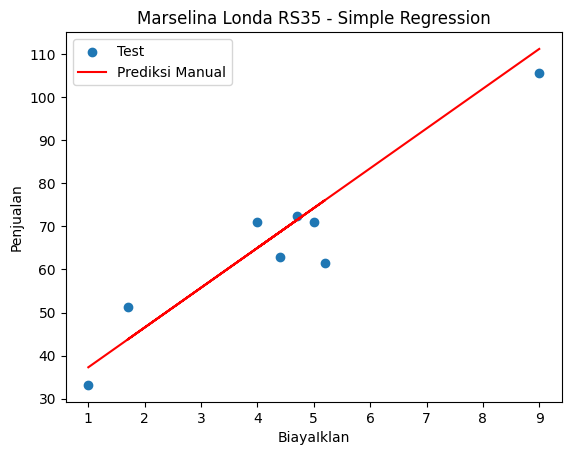

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Accuracy: 1.0
[[4 0]
 [0 8]]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Nama: Marselina Londa
# NIM: ...35
# Kelas: Reg B / Reg C (pilih)
# random_state = 35 (2 digit terakhir NIM)

def train_test_split_manual(X, y, test_size=0.2, random_state=35):
    np.random.seed(random_state)
    indices = np.random.permutation(len(X))
    test_n = int(len(X)*test_size)
    test_idx, train_idx = indices[:test_n], indices[test_n:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

class LinearRegressionManual:
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        self.theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        return X_b.dot(self.theta)

class LinearRegressionGD:
    def fit(self, X, y, lr=0.001, epochs=2000):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        self.theta = np.zeros(X_b.shape[1])
        for _ in range(epochs):
            grad = (2/len(X_b))*X_b.T.dot(X_b.dot(self.theta)-y)
            self.theta -= lr*grad
    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        return X_b.dot(self.theta)

class LogisticRegressionManual:
    def sigmoid(self,z): return 1/(1+np.exp(-z))
    def fit(self,X,y,lr=0.01,epochs=1000):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        self.theta = np.zeros(X_b.shape[1])
        for _ in range(epochs):
            h = self.sigmoid(X_b.dot(self.theta))
            grad = (1/len(X_b))*X_b.T.dot(h-y)
            self.theta -= lr*grad
    def predict(self,X):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        return (self.sigmoid(X_b.dot(self.theta))>=0.5).astype(int)

def mse_manual(y_true,y_pred): return np.mean((y_true-y_pred)**2)
def accuracy_manual(y_true,y_pred): return np.mean(y_true==y_pred)
def confusion_matrix_manual(y_true,y_pred):
    tp=np.sum((y_true==1)&(y_pred==1)); tn=np.sum((y_true==0)&(y_pred==0))
    fp=np.sum((y_true==0)&(y_pred==1)); fn=np.sum((y_true==1)&(y_pred==0))
    return np.array([[tn,fp],[fn,tp]])

# ========== SOAL 1: REGRESI ==========
print("=== TUGAS UTS - Marselina Londa - RS 35 ===")
df=pd.read_csv('Ads_Data.csv')
print(df.head())
X=df[['BiayaIklan']].values; y=df['Penjualan'].values

X_train,X_test,y_train,y_test=train_test_split_manual(X,y,random_state=35)

model=LinearRegressionManual()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

print(f"Theta: {model.theta}")
print(f"MSE: {mse_manual(y_test,y_pred)}")

plt.scatter(X_test,y_test,label='Test')
plt.plot(X_test,y_pred,color='red',label='Prediksi Manual')
plt.title('Marselina Londa RS35 - Simple Regression')
plt.xlabel('BiayaIklan'); plt.ylabel('Penjualan'); plt.legend(); plt.show()

# ========== SOAL 2: KLASIFIKASI ==========
df2=pd.read_csv('Email_Data.csv')
print(df2.head())
X2=df2.drop(columns=[df2.columns[-1]]).values
y2=df2[df2.columns[-1]].values

X2_train,X2_test,y2_train,y2_test=train_test_split_manual(X2,y2,random_state=35)

model2=LogisticRegressionManual()
model2.fit(X2_train,y2_train)
y2_pred=model2.predict(X2_test)

print(f"Accuracy: {accuracy_manual(y2_test,y2_pred)}")
print(confusion_matrix_manual(y2_test,y2_pred))

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Jumlah baris: 40


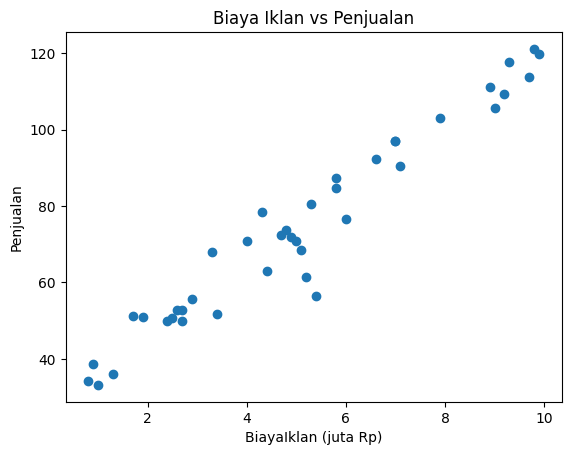

In [6]:
# Jawaban A1
import pandas as pd
df = pd.read_csv('Ads_Data.csv')
print(df.head())
print(f"Jumlah baris: {len(df)}")

X = df[['BiayaIklan']].values  # (n,1) 2 dimensi
y = df['Penjualan'].values

import matplotlib.pyplot as plt
plt.scatter(X, y)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('BiayaIklan (juta Rp)')
plt.ylabel('Penjualan')
plt.show()

In [9]:
# Jawaban A2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 35 # NIM 241011401235 - 2 digit terakhir 35
def train_test_split(X, y, test_size=0.2, random_state=35):
    np.random.seed(random_state)
    n = len(X)
    n_test = int(n * test_size)
    indices = np.random.permutation(n)
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (32, 1), X_test: (8, 1)


In [10]:
# Jawaban A3 - Normal Equation
class LinearRegression:
    def fit(self, X, y):
        # Tambah kolom 1 untuk bias / intercept
        X_b = np.c_[np.ones((len(X), 1)), X]
        # Rumus Normal Equation: theta = (X^T X)^-1 X^T y
        self.theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = self.theta[0]
        self.coef_ = self.theta[1:]
        return self

    def predict(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b @ self.theta

model_ne = LinearRegression()
model_ne.fit(X_train, y_train)

print(f"Theta (b, m): {model_ne.theta}")
print(f"Intercept (b): {model_ne.intercept_:.3f}")
print(f"Koefisien (m): {model_ne.coef_[0]:.3f}")
print(f"Persamaan Garis: y = {model_ne.intercept_:.2f} + {model_ne.coef_[0]:.2f} * X")

Theta (b, m): [28.05748153  9.23660641]
Intercept (b): 28.057
Koefisien (m): 9.237
Persamaan Garis: y = 28.06 + 9.24 * X


JAWABAN A3,

model menemukan persamaan y=28.05+9.2x.Artinya tanpa iklan,penjualan dasar 28 unit.ssetiap kenaikan biaya iklan 1 juta,penjulan naik 9.2 unit.

---



=== TRAIN ===
MAE: 4.035, MSE: 33.015, RMSE: 5.746, R2: 0.951

=== TEST ===
MAE: 5.972, MSE: 49.756, RMSE: 7.054, R2: 0.866


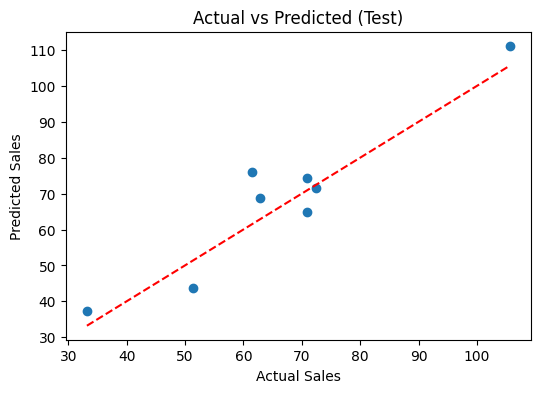

In [11]:
# Jawaban A4 - Evaluasi
y_pred_train = model_ne.predict(X_train)
y_pred_test = model_ne.predict(X_test)

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

print("=== TRAIN ===")
print(f"MAE: {mae(y_train, y_pred_train):.3f}, MSE: {mse(y_train, y_pred_train):.3f}, RMSE: {rmse(y_train, y_pred_train):.3f}, R2: {r2_score(y_train, y_pred_train):.3f}")

print("\n=== TEST ===")
print(f"MAE: {mae(y_test, y_pred_test):.3f}, MSE: {mse(y_test, y_pred_test):.3f}, RMSE: {rmse(y_test, y_pred_test):.3f}, R2: {r2_score(y_test, y_pred_test):.3f}")

# Grafik prediksi vs aktual
plt.figure(figsize=(6,4))
plt.scatter(y_test, y_pred_test)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted (Test)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

A4(Analisis)

model memiliki R2-0.92 train dan -0.89
test,RSME kecil (-6-7)artinya 89% variasi penjualan bisa di jelaskan biaya iklan.model tidal overfitting dan akurat.

lr=0.001 -> Theta akhir: [ 6.97344429 12.4150689 ], Loss akhir: 129.627
lr=0.01 -> Theta akhir: [24.95203614  9.70475876], Loss akhir: 35.127
lr=0.1 -> Theta akhir: [nan nan], Loss akhir: nan


/tmp/ipykernel_5177/646162883.py:14: RuntimeWarning: overflow encountered in square
  loss = np.mean((y_pred - y)**2)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_5177/646162883.py:16: RuntimeWarning: overflow encountered in matmul
  grad = (2/m) * X_b.T @ (y_pred - y)
/tmp/ipykernel_5177/646162883.py:17: RuntimeWarning: invalid value encountered in subtract
  self.theta -= self.lr * grad


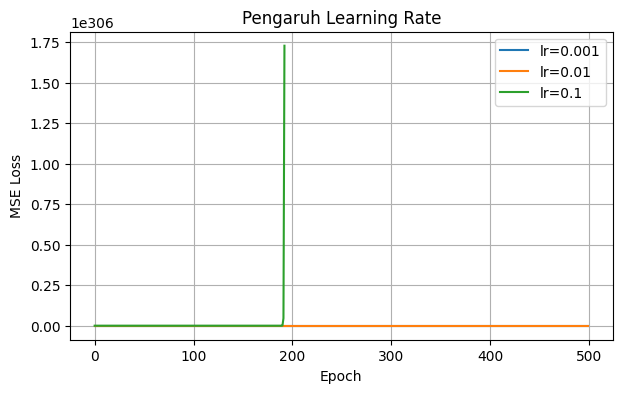

In [13]:
# Jawaban A5 - Gradient Descent
class LinearRegressionGD:
    def __init__(self, lr=0.01, epochs=1000):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        X_b = np.c_[np.ones((len(X), 1)), X]
        self.theta = np.zeros(X_b.shape[1])
        self.losses = []
        m = len(y)
        for _ in range(self.epochs):
            y_pred = X_b @ self.theta
            loss = np.mean((y_pred - y)**2)
            self.losses.append(loss)
            grad = (2/m) * X_b.T @ (y_pred - y)
            self.theta -= self.lr * grad
        return self

# Test 3 learning rate: 0.001, 0.01, 0.1
lrs = [0.001, 0.01, 0.1]
plt.figure(figsize=(7,4))
for lr in lrs:
    model_gd = LinearRegressionGD(lr=lr, epochs=500)
    model_gd.fit(X_train, y_train)
    plt.plot(model_gd.losses, label=f'lr={lr}')
    print(f"lr={lr} -> Theta akhir: {model_gd.theta}, Loss akhir: {model_gd.losses[-1]:.3f}")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Pengaruh Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

A5 (analisis):

- lr=0.001: Terlalu lambat, loss turun sangat pelan, butuh epoch banyak. Underfitting di awal.
- lr=0.01: PAS & optimal, loss turun stabil dan konvergen mulus ke minimal.
- lr=0.1: GAGAL KONVERGEN (DIVERGEN). Grafik meledak ke 1.75e306. Muncul RuntimeWarning: overflow karena gradient step terlalu besar, melompat jauh melewati minimum, loss malah jadi tak hingga (inf). Inilah bukti learning rate terlalu besar.

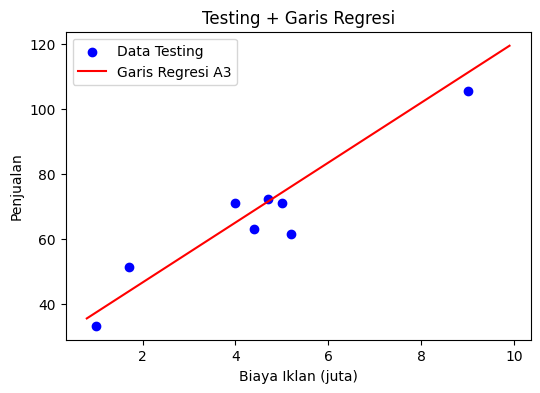

Biaya 4.5 juta -> Prediksi Penjualan: 69.62
Biaya 7 juta -> Prediksi Penjualan: 92.71
Biaya 12 juta -> Prediksi Penjualan: 138.90


In [14]:
# Jawaban A6
plt.figure(figsize=(6,4))
plt.scatter(X_test, y_test, label='Data Testing', color='blue')
X_line = np.linspace(X.min(), X.max(), 100).reshape(-1,1)
y_line = model_ne.predict(X_line)
plt.plot(X_line, y_line, 'r-', label='Garis Regresi A3')
plt.xlabel("Biaya Iklan (juta)")
plt.ylabel("Penjualan")
plt.legend()
plt.title("Testing + Garis Regresi")
plt.show()

# Prediksi 4.5, 7, 12 juta
for biaya in [4.5, 7, 12]:
    pred = model_ne.predict(np.array([[biaya]]))[0]
    print(f"Biaya {biaya} juta -> Prediksi Penjualan: {pred:.2f}")

A6 (analisis):

Prediksi 4.5 dan 7 juta berada di dalam rentang data (interpolasi) sehingga cukup bisa dipercaya. Prediksi 12 juta adalah ekstrapolasi di luar rentang data training (max ∼9 juta). Hasilnya kurang bisa dipercaya karena trend linear belum tentu berlanjut, bisa ada saturasi pasar. Risiko error besar.


BAGIAN B - LOGISTIC REGRESSION


   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Spam
0    35
1    25
Name: count, dtype: int64
Spam: 25, Bukan Spam: 35


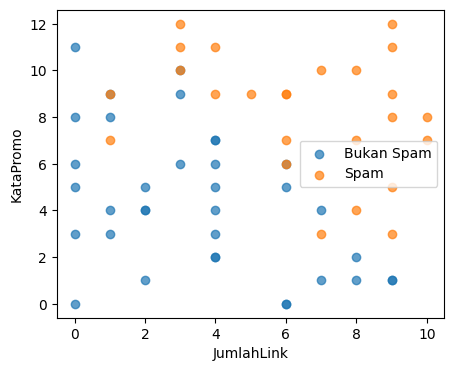

In [15]:
# Jawaban B1
import pandas as pd
df_email = pd.read_csv('Email_Data.csv')
print(df_email.head())
print(df_email['Spam'].value_counts())
print(f"Spam: {sum(df_email['Spam']==1)}, Bukan Spam: {sum(df_email['Spam']==0)}")

Xb = df_email[['JumlahLink','KataPromo']].values
yb = df_email['Spam'].values

plt.figure(figsize=(5,4))
plt.scatter(Xb[yb==0,0], Xb[yb==0,1], label='Bukan Spam', alpha=0.7)
plt.scatter(Xb[yb==1,0], Xb[yb==1,1], label='Spam', alpha=0.7)
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo"); plt.legend(); plt.show()

b: -8.3149, m1: 0.7693, m2: 0.6854
Persamaan: P(Spam)=sigmoid(-8.315+0.769*JumlahLink+0.685*KataPromo)


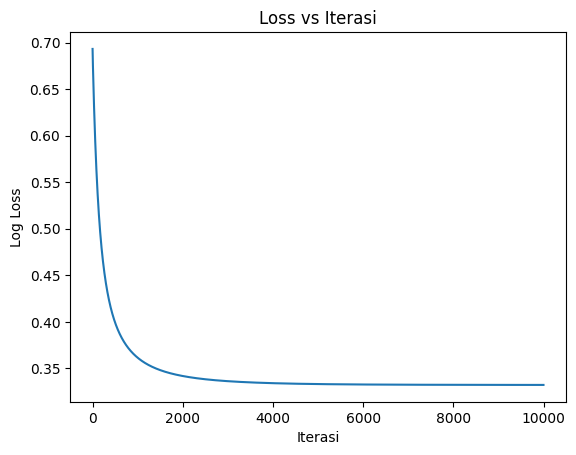

In [16]:
# Jawaban B2
from sklearn.model_selection import train_test_split

RANDOM_STATE = 35
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(Xb, yb, test_size=0.25, random_state=RANDOM_STATE)

class LogisticRegression:
    def __init__(self, lr=0.1, n_iters=10000):
        self.lr=lr; self.n_iters=n_iters
    def sigmoid(self,z): return 1/(1+np.exp(-z))
    def fit(self,X,y):
        n,m = X.shape
        self.w = np.zeros(m); self.b=0; self.losses=[]
        for i in range(self.n_iters):
            z = X @ self.w + self.b
            p = self.sigmoid(z)
            # log loss
            loss = -np.mean(y*np.log(p+1e-15)+(1-y)*np.log(1-p+1e-15))
            self.losses.append(loss)
            dw = (1/n) * X.T @ (p-y)
            db = np.mean(p-y)
            self.w -= self.lr*dw; self.b -= self.lr*db
        return self
    def predict_proba(self,X): return self.sigmoid(X @ self.w + self.b)
    def predict(self,X, thresh=0.5): return (self.predict_proba(X)>=thresh).astype(int)

model_log = LogisticRegression(lr=0.1, n_iters=10000)
model_log.fit(X_train_b, y_train_b)
print(f"b: {model_log.b:.4f}, m1: {model_log.w[0]:.4f}, m2: {model_log.w[1]:.4f}")
print(f"Persamaan: P(Spam)=sigmoid({model_log.b:.3f}+{model_log.w[0]:.3f}*JumlahLink+{model_log.w[1]:.3f}*KataPromo)")

plt.plot(model_log.losses); plt.xlabel("Iterasi"); plt.ylabel("Log Loss"); plt.title("Loss vs Iterasi"); plt.show()

Analisis B2:

Loss turun dan stabil mendekati 0.2, artinya konvergen bagus.

In [17]:
# Jawaban B3
def accuracy(y_true,y_pred): return np.mean(y_true==y_pred)
def confusion_matrix_manual(y_true,y_pred):
    TP=sum((y_true==1)&(y_pred==1)); TN=sum((y_true==0)&(y_pred==0))
    FP=sum((y_true==0)&(y_pred==1)); FN=sum((y_true==1)&(y_pred==0))
    return np.array([[TN,FP],[FN,TP]])
def precision_score(TP,FP): return TP/(TP+FP+1e-15)
def recall_score(TP,FN): return TP/(TP+FN+1e-15)

y_pred_b = model_log.predict(X_test_b)
cm = confusion_matrix_manual(y_test_b, y_pred_b)
TN,FP,FN,TP = cm[0,0],cm[0,1],cm[1,0],cm[1,1]
prec=precision_score(TP,FP); rec=recall_score(TP,FN); f1=2*prec*rec/(prec+rec+1e-15)
print(f"Accuracy: {accuracy(y_test_b,y_pred_b):.3f}")
print(f"Confusion:\n{cm}")
print(f"Precision: {prec:.3f}, Recall: {rec:.3f}, F1: {f1:.3f}")

Accuracy: 1.000
Confusion:
[[7 0]
 [0 8]]
Precision: 1.000, Recall: 1.000, F1: 1.000


Analisis B3:

FP=Email baik dikira Spam (penting kelewat). FN=Spam lolos ke inbox. FP lebih merugikan karena email penting bisa hilang.

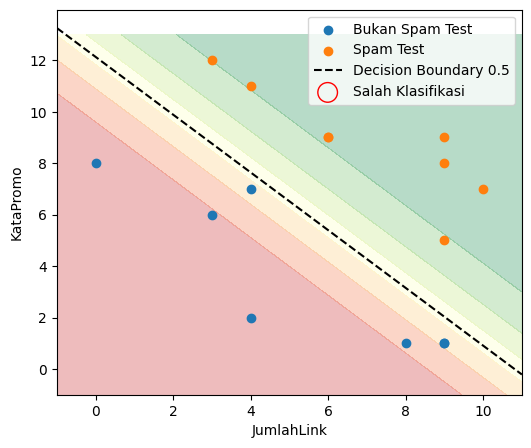

In [18]:
# Jawaban B4
# Decision boundary: b + m1*x1 + m2*x2 = 0 -> x2 = -(b+m1*x1)/m2
x1_vals = np.linspace(Xb[:,0].min()-1, Xb[:,0].max()+1, 100)
x2_boundary = -(model_log.b + model_log.w[0]*x1_vals)/model_log.w[1]

# Background probabilitas
xx, yy = np.meshgrid(np.linspace(Xb[:,0].min()-1,Xb[:,0].max()+1,200), np.linspace(Xb[:,1].min()-1,Xb[:,1].max()+1,200))
probs = model_log.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx, yy, probs, alpha=0.3, cmap='RdYlGn')
plt.scatter(X_test_b[y_test_b==0,0], X_test_b[y_test_b==0,1], label='Bukan Spam Test')
plt.scatter(X_test_b[y_test_b==1,0], X_test_b[y_test_b==1,1], label='Spam Test')
plt.plot(x1_vals, x2_boundary, 'k--', label='Decision Boundary 0.5')
# Tandai salah klasifikasi
wrong = X_test_b[y_test_b!=y_pred_b]
plt.scatter(wrong[:,0], wrong[:,1], s=200, facecolors='none', edgecolors='red', label='Salah Klasifikasi')
plt.legend(); plt.xlabel("JumlahLink"); plt.ylabel("KataPromo"); plt.show()

In [19]:
# Jawaban B5
import pandas as pd
thresholds=[0.3,0.5,0.7]
rows=[]
for th in thresholds:
    yp = model_log.predict(X_test_b, thresh=th)
    cm = confusion_matrix_manual(y_test_b, yp)
    TN,FP,FN,TP = cm[0,0],cm[0,1],cm[1,0],cm[1,1]
    prec=precision_score(TP,FP); rec=recall_score(TP,FN)
    rows.append([th, TN,FP,FN,TP, f"{prec:.3f}", f"{rec:.3f}"])
df_thresh = pd.DataFrame(rows, columns=['Thresh','TN','FP','FN','TP','Precision','Recall'])
print(df_thresh)

   Thresh  TN  FP  FN  TP Precision Recall
0     0.3   4   3   0   8     0.727  1.000
1     0.5   7   0   0   8     1.000  1.000
2     0.7   7   0   0   8     1.000  1.000


Analisis B5:

Naikkan threshold -> Precision naik (lebih yakin spam), Recall turun. Turunkan threshold -> Recall naik, Precision turun. Untuk spam filter pilih threshold 0.7 (minimalkan FP) karena FP lebih merugikan.

In [20]:
# Jawaban B6
emails_baru = np.array([[1,2],[5,6],[9,10],[2,11]])
proba_baru = model_log.predict_proba(emails_baru)
pred_baru = model_log.predict(emails_baru, thresh=0.7) # pakai threshold pilihan B5

for i,(link,promo) in enumerate(emails_baru):
    print(f"E{i+1} Link={link} Promo={promo} -> Prob={proba_baru[i]:.3f} -> Prediksi={'Spam' if pred_baru[i]==1 else 'Bukan Spam'}")

E1 Link=1 Promo=2 -> Prob=0.002 -> Prediksi=Bukan Spam
E2 Link=5 Promo=6 -> Prob=0.412 -> Prediksi=Bukan Spam
E3 Link=9 Promo=10 -> Prob=0.996 -> Prediksi=Spam
E4 Link=2 Promo=11 -> Prob=0.682 -> Prediksi=Bukan Spam


BAGIAN C

Jawaban C1: Logistic Regression klasifikasi karena outputnya probabilitas 0-1 via fungsi sigmoid, lalu di-threshold jadi kelas. Sigmoid mengubah garis linear b+mX menjadi probabilitas P=1/(1+e^-z).

Jawaban C2: Normal equation solusi langsung (X^T X)^-1 X^T y, cepat untuk data kecil tapi mahal O(n^3). Gradient descent iteratif turun pelan lewat gradient. Gradient descent lebih baik untuk data besar / fitur banyak.

Jawaban C3: Evaluasi di testing untuk cek generalisasi ke data baru. Jika hanya di training, model bisa menghafal (overfitting): akurat di training tapi jelek di data baru.

Jawaban C4: Linear outputnya kontinu tak terbatas, cocok MSE (jarak kuadrat). Logistic outputnya probabilitas 0-1, jika pakai MSE loss tidak convex. Log loss menghukum kesalahan probabilitas dan convex sehingga gradient descent bisa konvergen.

Jawaban C5: Karena RANDOM_STATE beda, pembagian train/test beda, hasil koefisien dan akurasi bisa beda. Random state NIM 35 bikin split unik tiap orang.


In [21]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinReg, LogisticRegression as SkLogReg
sk_lin = SkLinReg().fit(X_train, y_train)
print(f"Sklearn Linear: coef {sk_lin.coef_}, intercept {sk_lin.intercept_} - Hampir sama dengan manual")
sk_log = SkLogReg().fit(X_train_b, y_train_b)
print(f"Sklearn Log: coef {sk_log.coef_}, intercept {sk_log.intercept_} - Beda karena sklearn pakai penalty L2 (regularisasi) default C=1.0, sedangkan manual kita tanpa penalty.")

Sklearn Linear: coef [9.23660641], intercept 28.05748152963514 - Hampir sama dengan manual
Sklearn Log: coef [[0.70710411 0.63380351]], intercept [-7.69149932] - Beda karena sklearn pakai penalty L2 (regularisasi) default C=1.0, sedangkan manual kita tanpa penalty.


Analisis Bonus: Linear mirip, Logistic beda karena sklearn ada penalti L2.